# SpaLMC
Run the model and visualize cell locations.

## 1. Setup
Import SpaLMC and plotting tools.

In [1]:
from pathlib import Path
import os
import sys
os.environ.setdefault('MKL_THREADING_LAYER', 'SEQUENTIAL')
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
import matplotlib
matplotlib.use('Agg')
candidates = [Path.cwd(), Path.cwd() / 'SpaLMC_release', *Path.cwd().parents]
ROOT = next(p.resolve() for p in candidates if (p / 'src/spalmc/workflow.py').exists())
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import torch
import spalmc
from IPython.display import display, Image
from spalmc.workflow import (
    read_config, load_inputs, fit_stage1, save_stage1,
    fit_occupied, predict_occupied, save_occupied,
    export_results, observed_from_model, arrays,
)
from spalmc import visualization as viz
assert Path(spalmc.__file__).resolve().is_relative_to(ROOT / 'src'), 'Restart the kernel and run this notebook again.'
torch.set_num_threads(2)
def show(path):
    display(Image(filename=str(path)))
print('SpaLMC is ready.')

SpaLMC is ready.


## 2. Configuration
Choose datasets and load checkpoints, or train from scratch.

In [2]:
MODE = 'pretrained'  # Set to 'train' to train both stages from scratch.
DATASETS = ['seqFISH+_res500', 'STARmap_res900']
SHOW_REFERENCE = True  # Display reference coordinates when available.
CFG = read_config(ROOT / 'configs/default.yml')
CFG['datasets'] = [d for d in CFG['datasets'] if d['name'] in DATASETS]
OUT = ROOT / 'outputs' / ('notebook_' + MODE + '_visualization')
OUT.mkdir(parents=True, exist_ok=True)
assert MODE in {'train', 'pretrained'}
assert CFG['datasets'], 'Choose at least one available dataset.'
RUNS = {}
print('Mode:', MODE)
print('Output:', OUT.relative_to(ROOT))

Mode: pretrained
Output: outputs\notebook_pretrained_visualization


## 3. Load data
Read reference expression, spot expression, and spot coordinates.

In [3]:
for spec in CFG['datasets']:
    sc, sp = load_inputs(spec['observed'])
    folder = OUT / spec['name']
    folder.mkdir(parents=True, exist_ok=True)
    RUNS[spec['name']] = dict(spec=spec, sc=sc, sp=sp, folder=folder)
    print(spec['name'], '| Cells:', sc.n_obs, '| Spots:', sp.n_obs, '| Genes:', sc.n_vars)

seqFISH+_res500 | Cells: 523 | Spots: 100 | Genes: 1000
STARmap_res900 | Cells: 1207 | Spots: 198 | Genes: 1000


## 4. Expression integration
Train or load the shared expression model and assign cells to spots.

In [4]:
for name, run in RUNS.items():
    checkpoint = run['spec']['stage1_checkpoint'] if MODE == 'pretrained' else None
    run['model'] = fit_stage1(run['sc'], run['sp'], CFG['model'], CFG['training'], checkpoint=checkpoint)
    save_stage1(run['model'], run['folder'] / 'checkpoints/stage1.pt')
    print(name, '| Expression integration complete.')

seqFISH+_res500 | Expression integration complete.
STARmap_res900 | Expression integration complete.


C:\Users\DELL\Desktop\吴尤论文投稿\Image integration\spalmc\output\github_publish_spalmc\src\spalmc\model.py:227: RuntimeWarning: Composition loss requested but cell type labels or spot prior are missing; `loss_comp` will be skipped.
  warnings.warn(
C:\Users\DELL\Desktop\吴尤论文投稿\Image integration\spalmc\output\github_publish_spalmc\src\spalmc\model.py:227: RuntimeWarning: Composition loss requested but cell type labels or spot prior are missing; `loss_comp` will be skipped.
  warnings.warn(


## 5. Cell localization
Train or load the coordinate decoder and save cell locations.

In [5]:
for name, run in RUNS.items():
    checkpoint = run['spec']['occupied_checkpoint'] if MODE == 'pretrained' else None
    decoder, context, history = fit_occupied(run['model'], CFG['occupied'], checkpoint=checkpoint)
    prediction, _ = predict_occupied(run['model'], decoder, context, CFG['occupied'])
    save_occupied(run['model'], decoder, CFG['occupied'], history, run['folder'] / 'checkpoints/occupied.pt')
    run['prediction'] = prediction
    run['observed'] = observed_from_model(run['model'])
    run['cells'] = export_results(run['model'], prediction, run['folder'], dict(dataset=name, mode=MODE))
    print(name, '| Cell locations saved.')

seqFISH+_res500 | Cell locations saved.
STARmap_res900 | Cell locations saved.


## 6. Overall visualization
Plot predicted cell locations and optional reference coordinates.

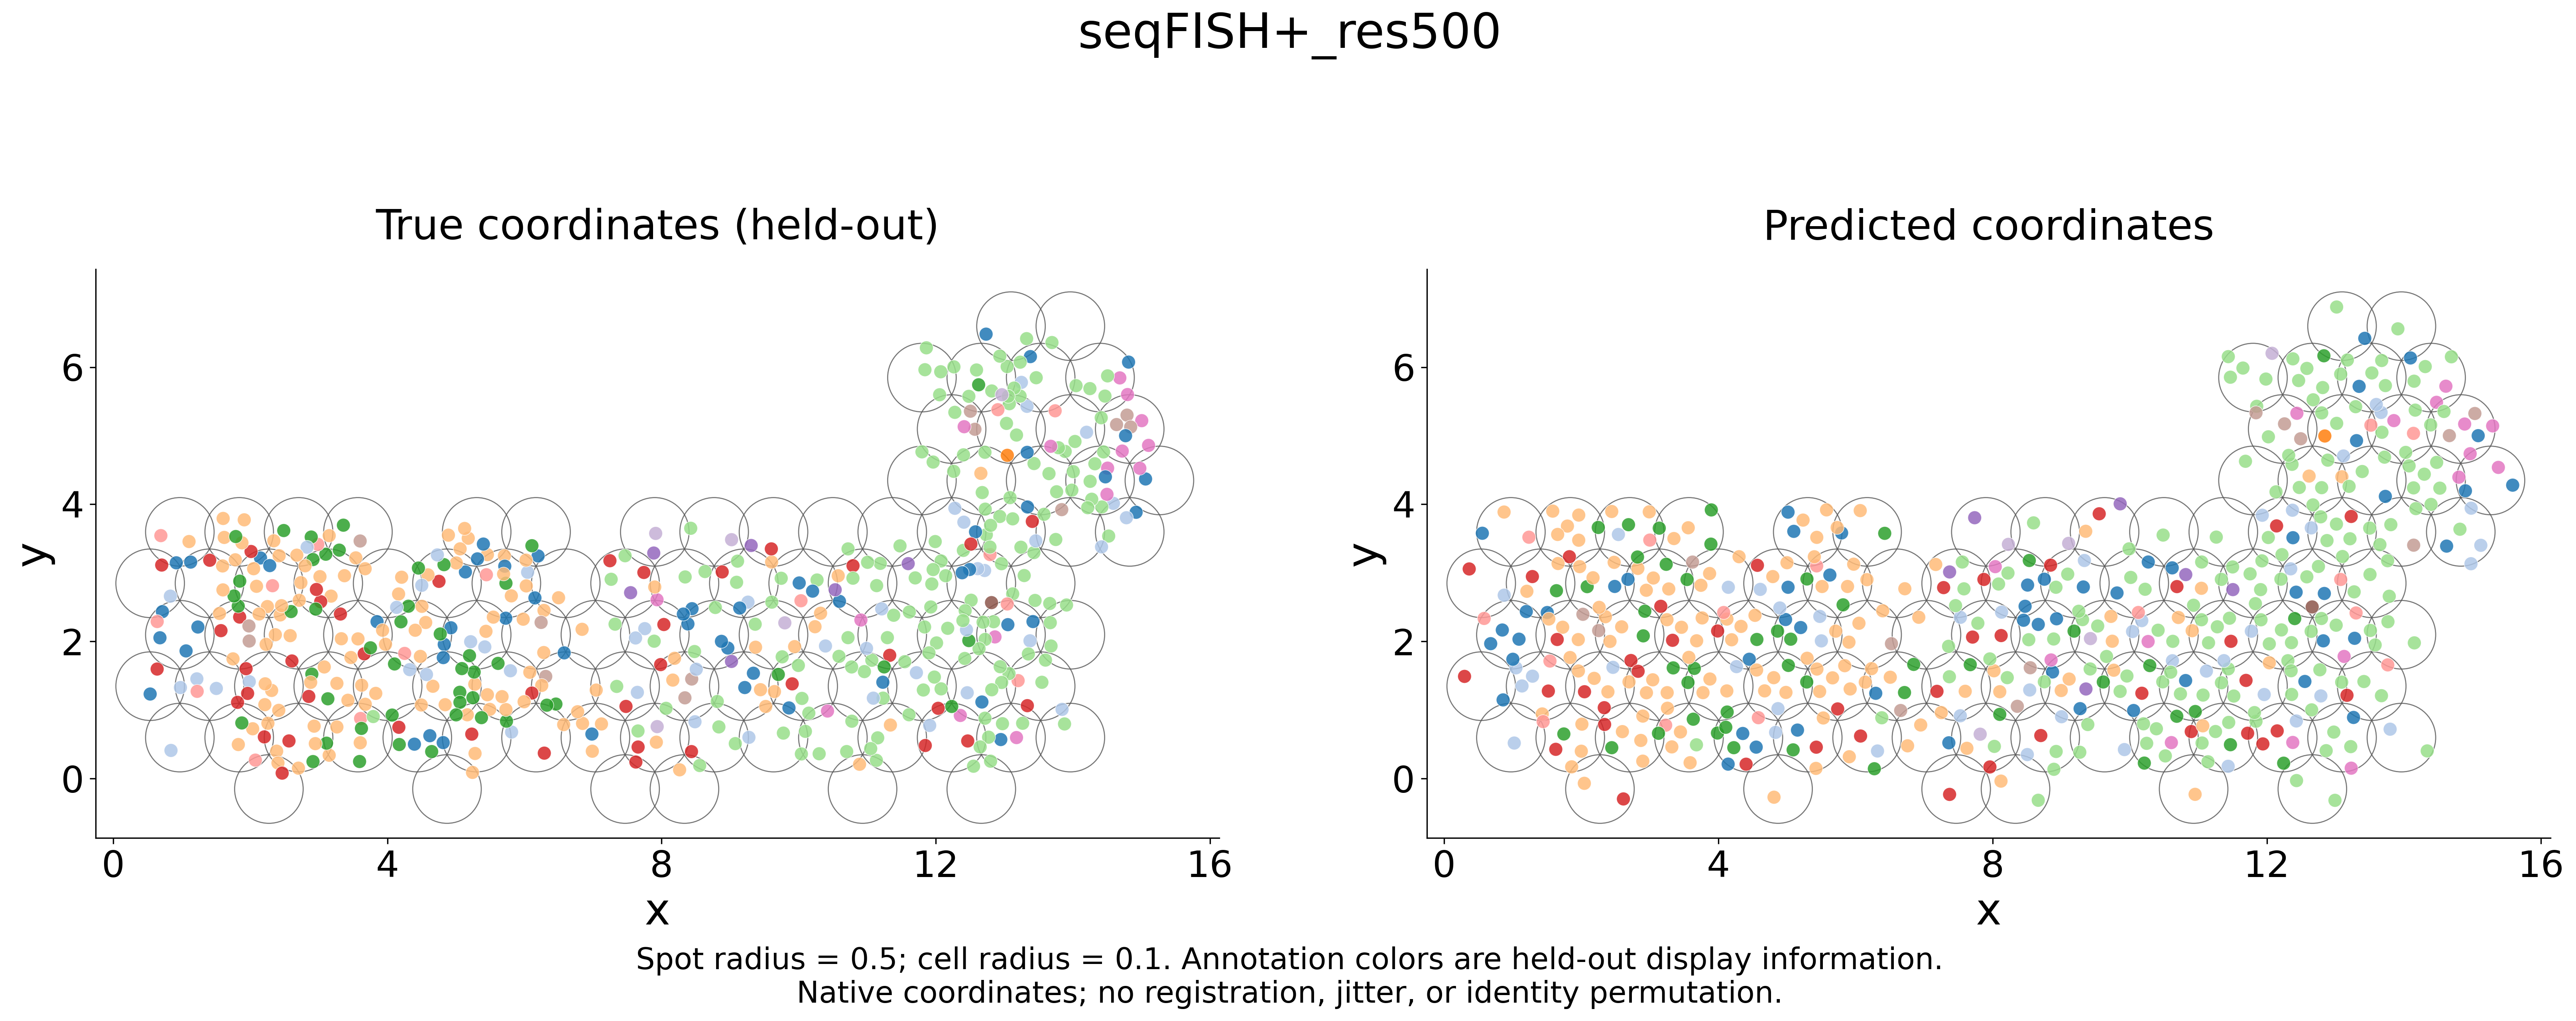

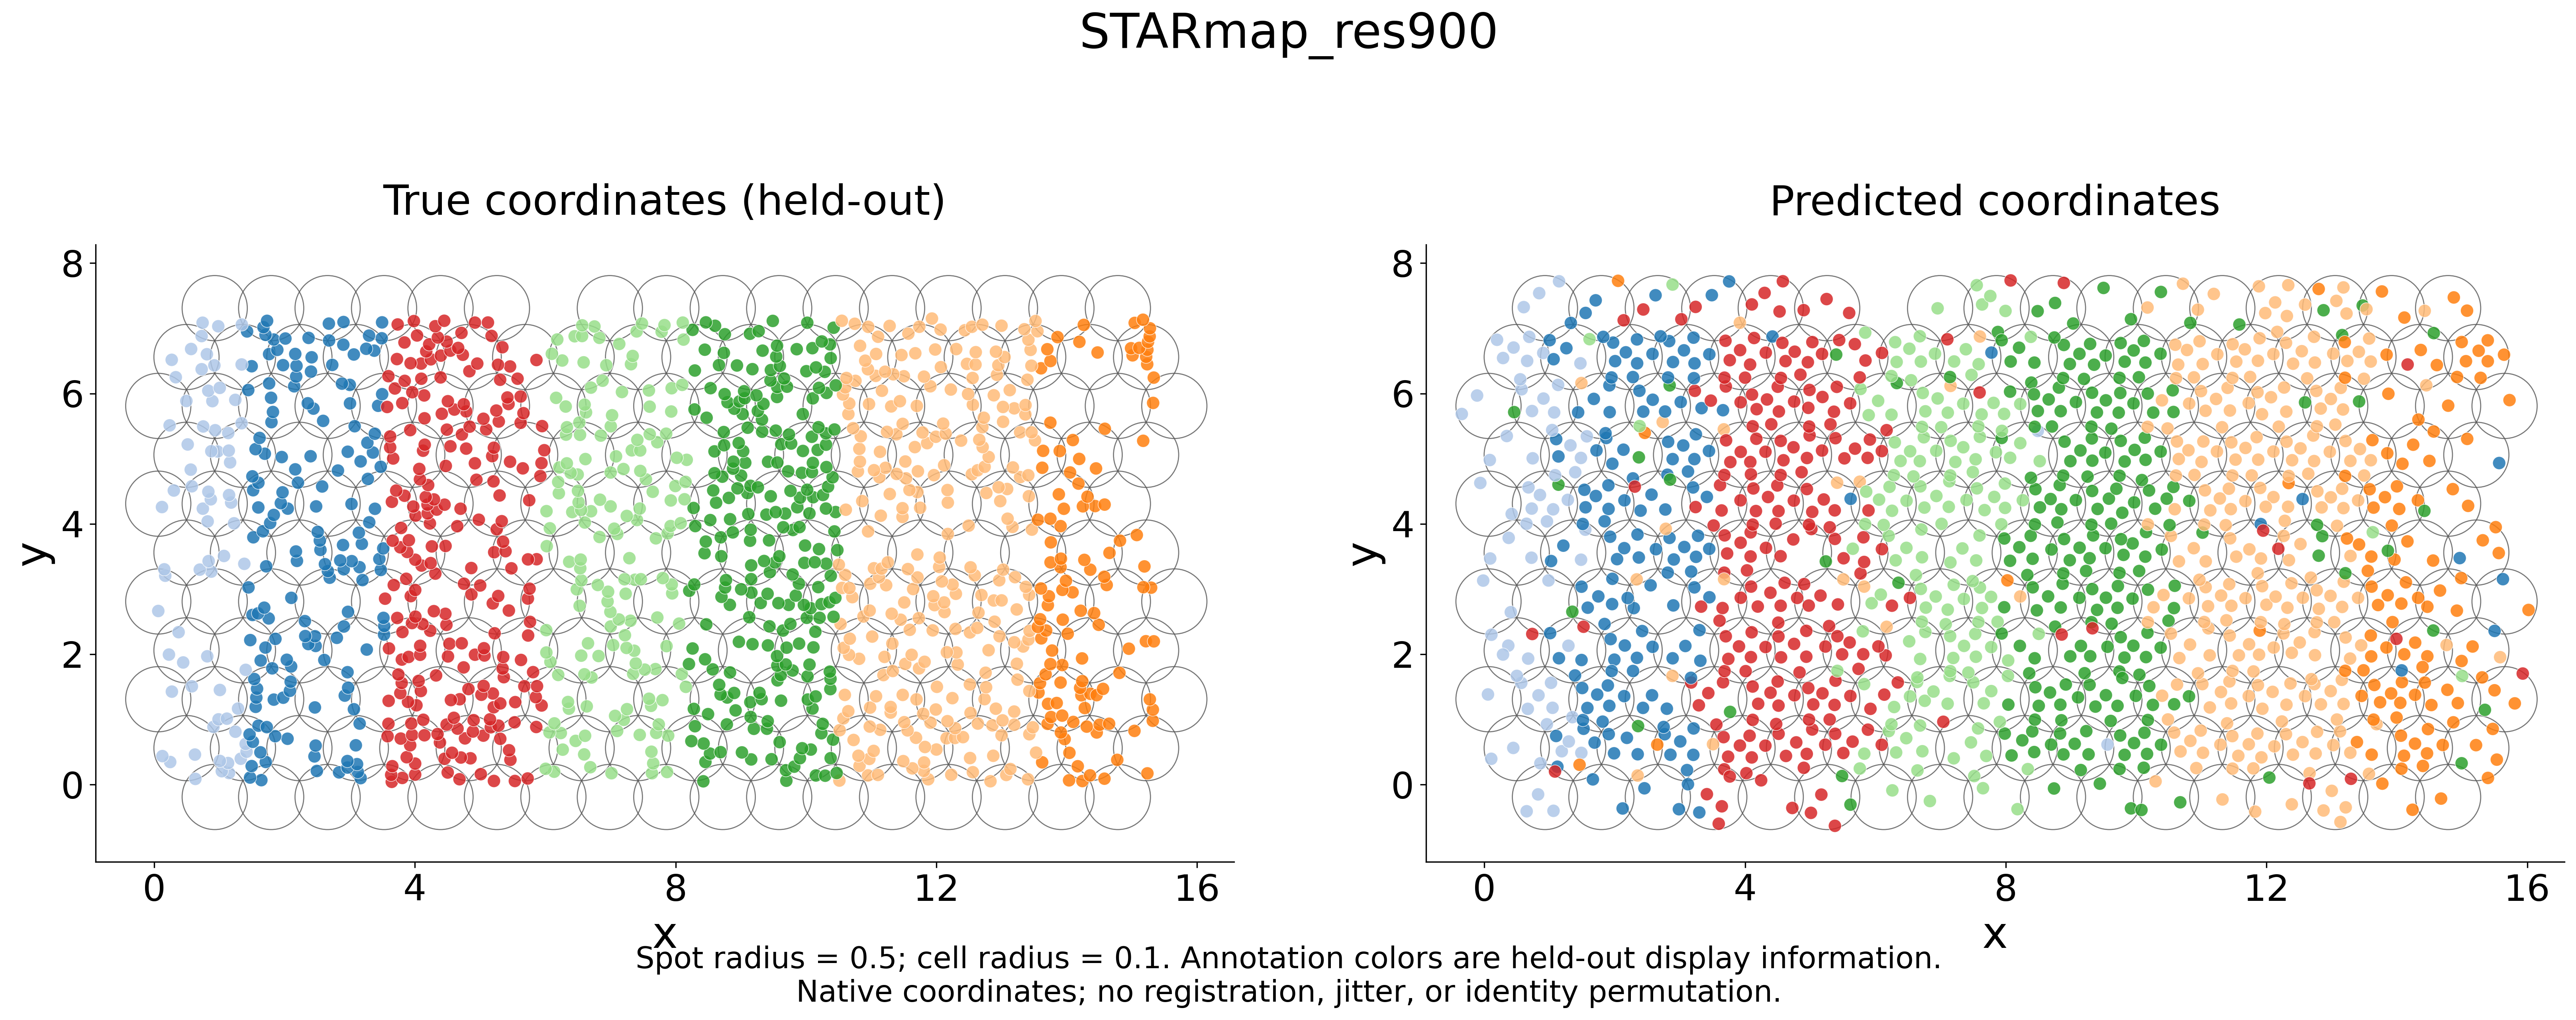

In [6]:
for name, run in RUNS.items():
    truth_path = run['spec'].get('truth')
    run['truth'] = arrays(truth_path) if SHOW_REFERENCE and truth_path and Path(truth_path).exists() else None
    show(viz.plot_overview(run['observed'], run['prediction'], run['truth'], run['folder'] / 'figures', name))

## 7. Within-spot visualization
Inspect one spot and its assigned cells. Set a spot index in SPOTS to choose another spot.

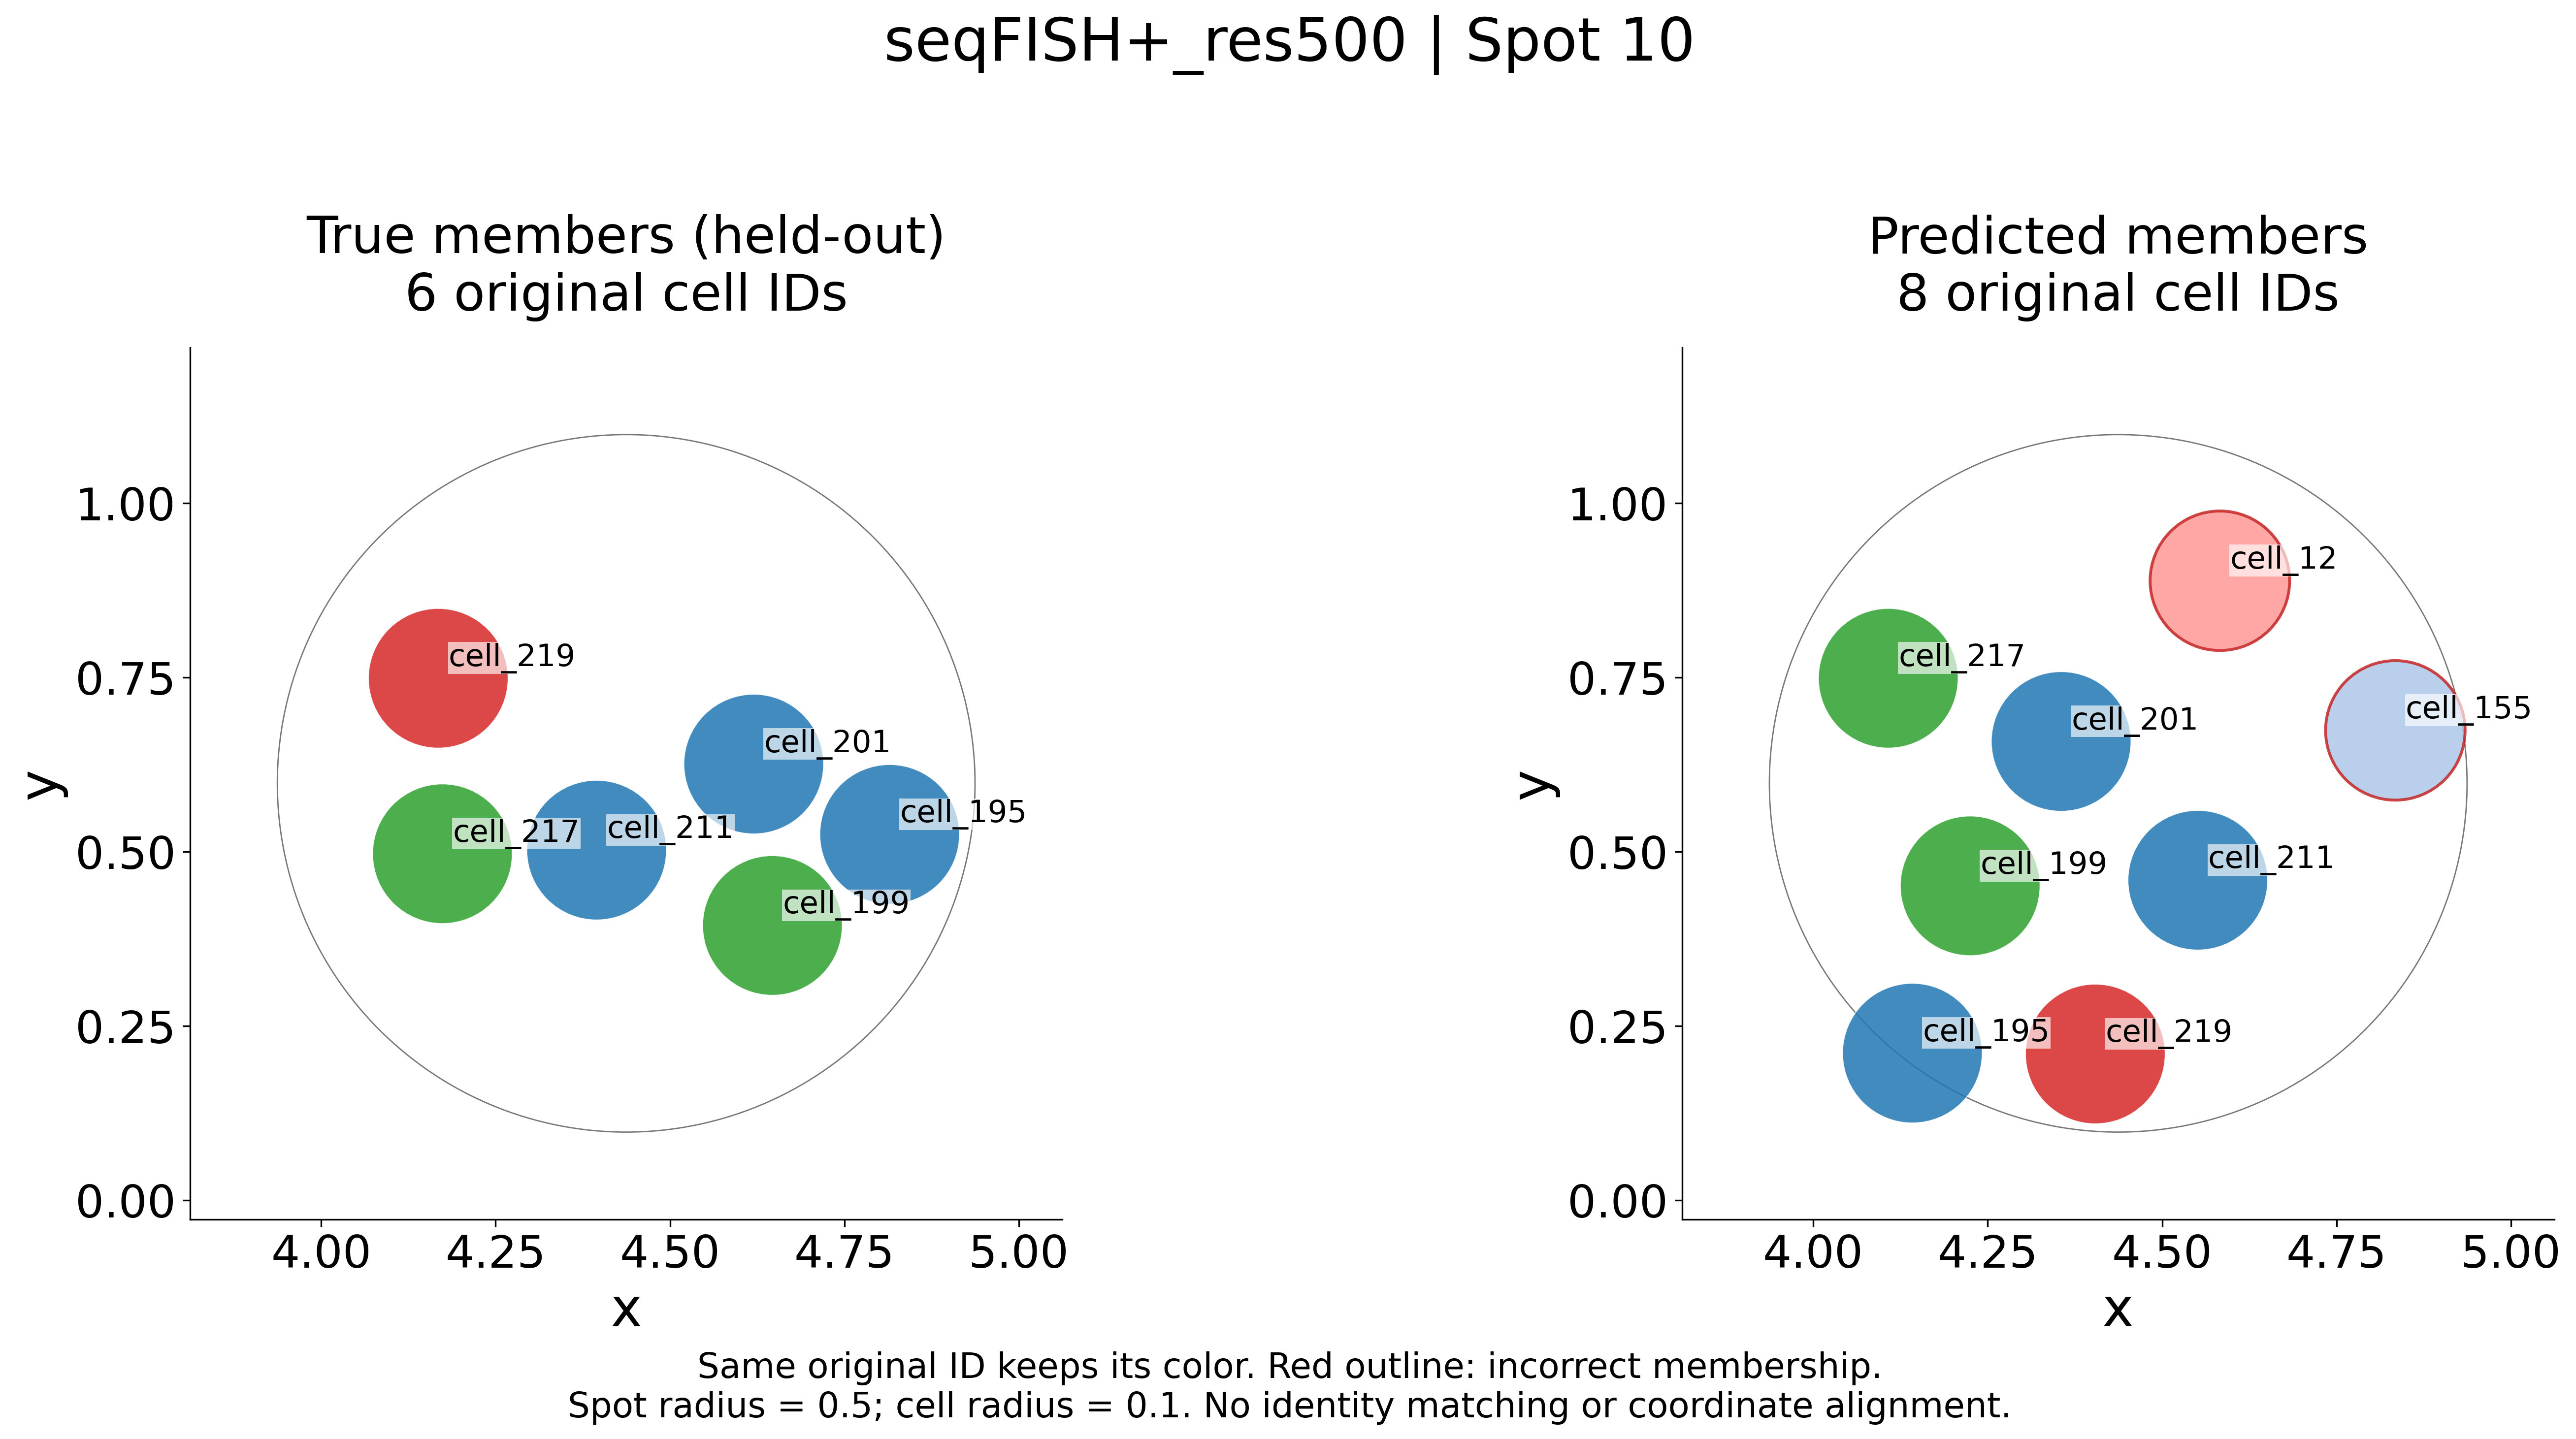

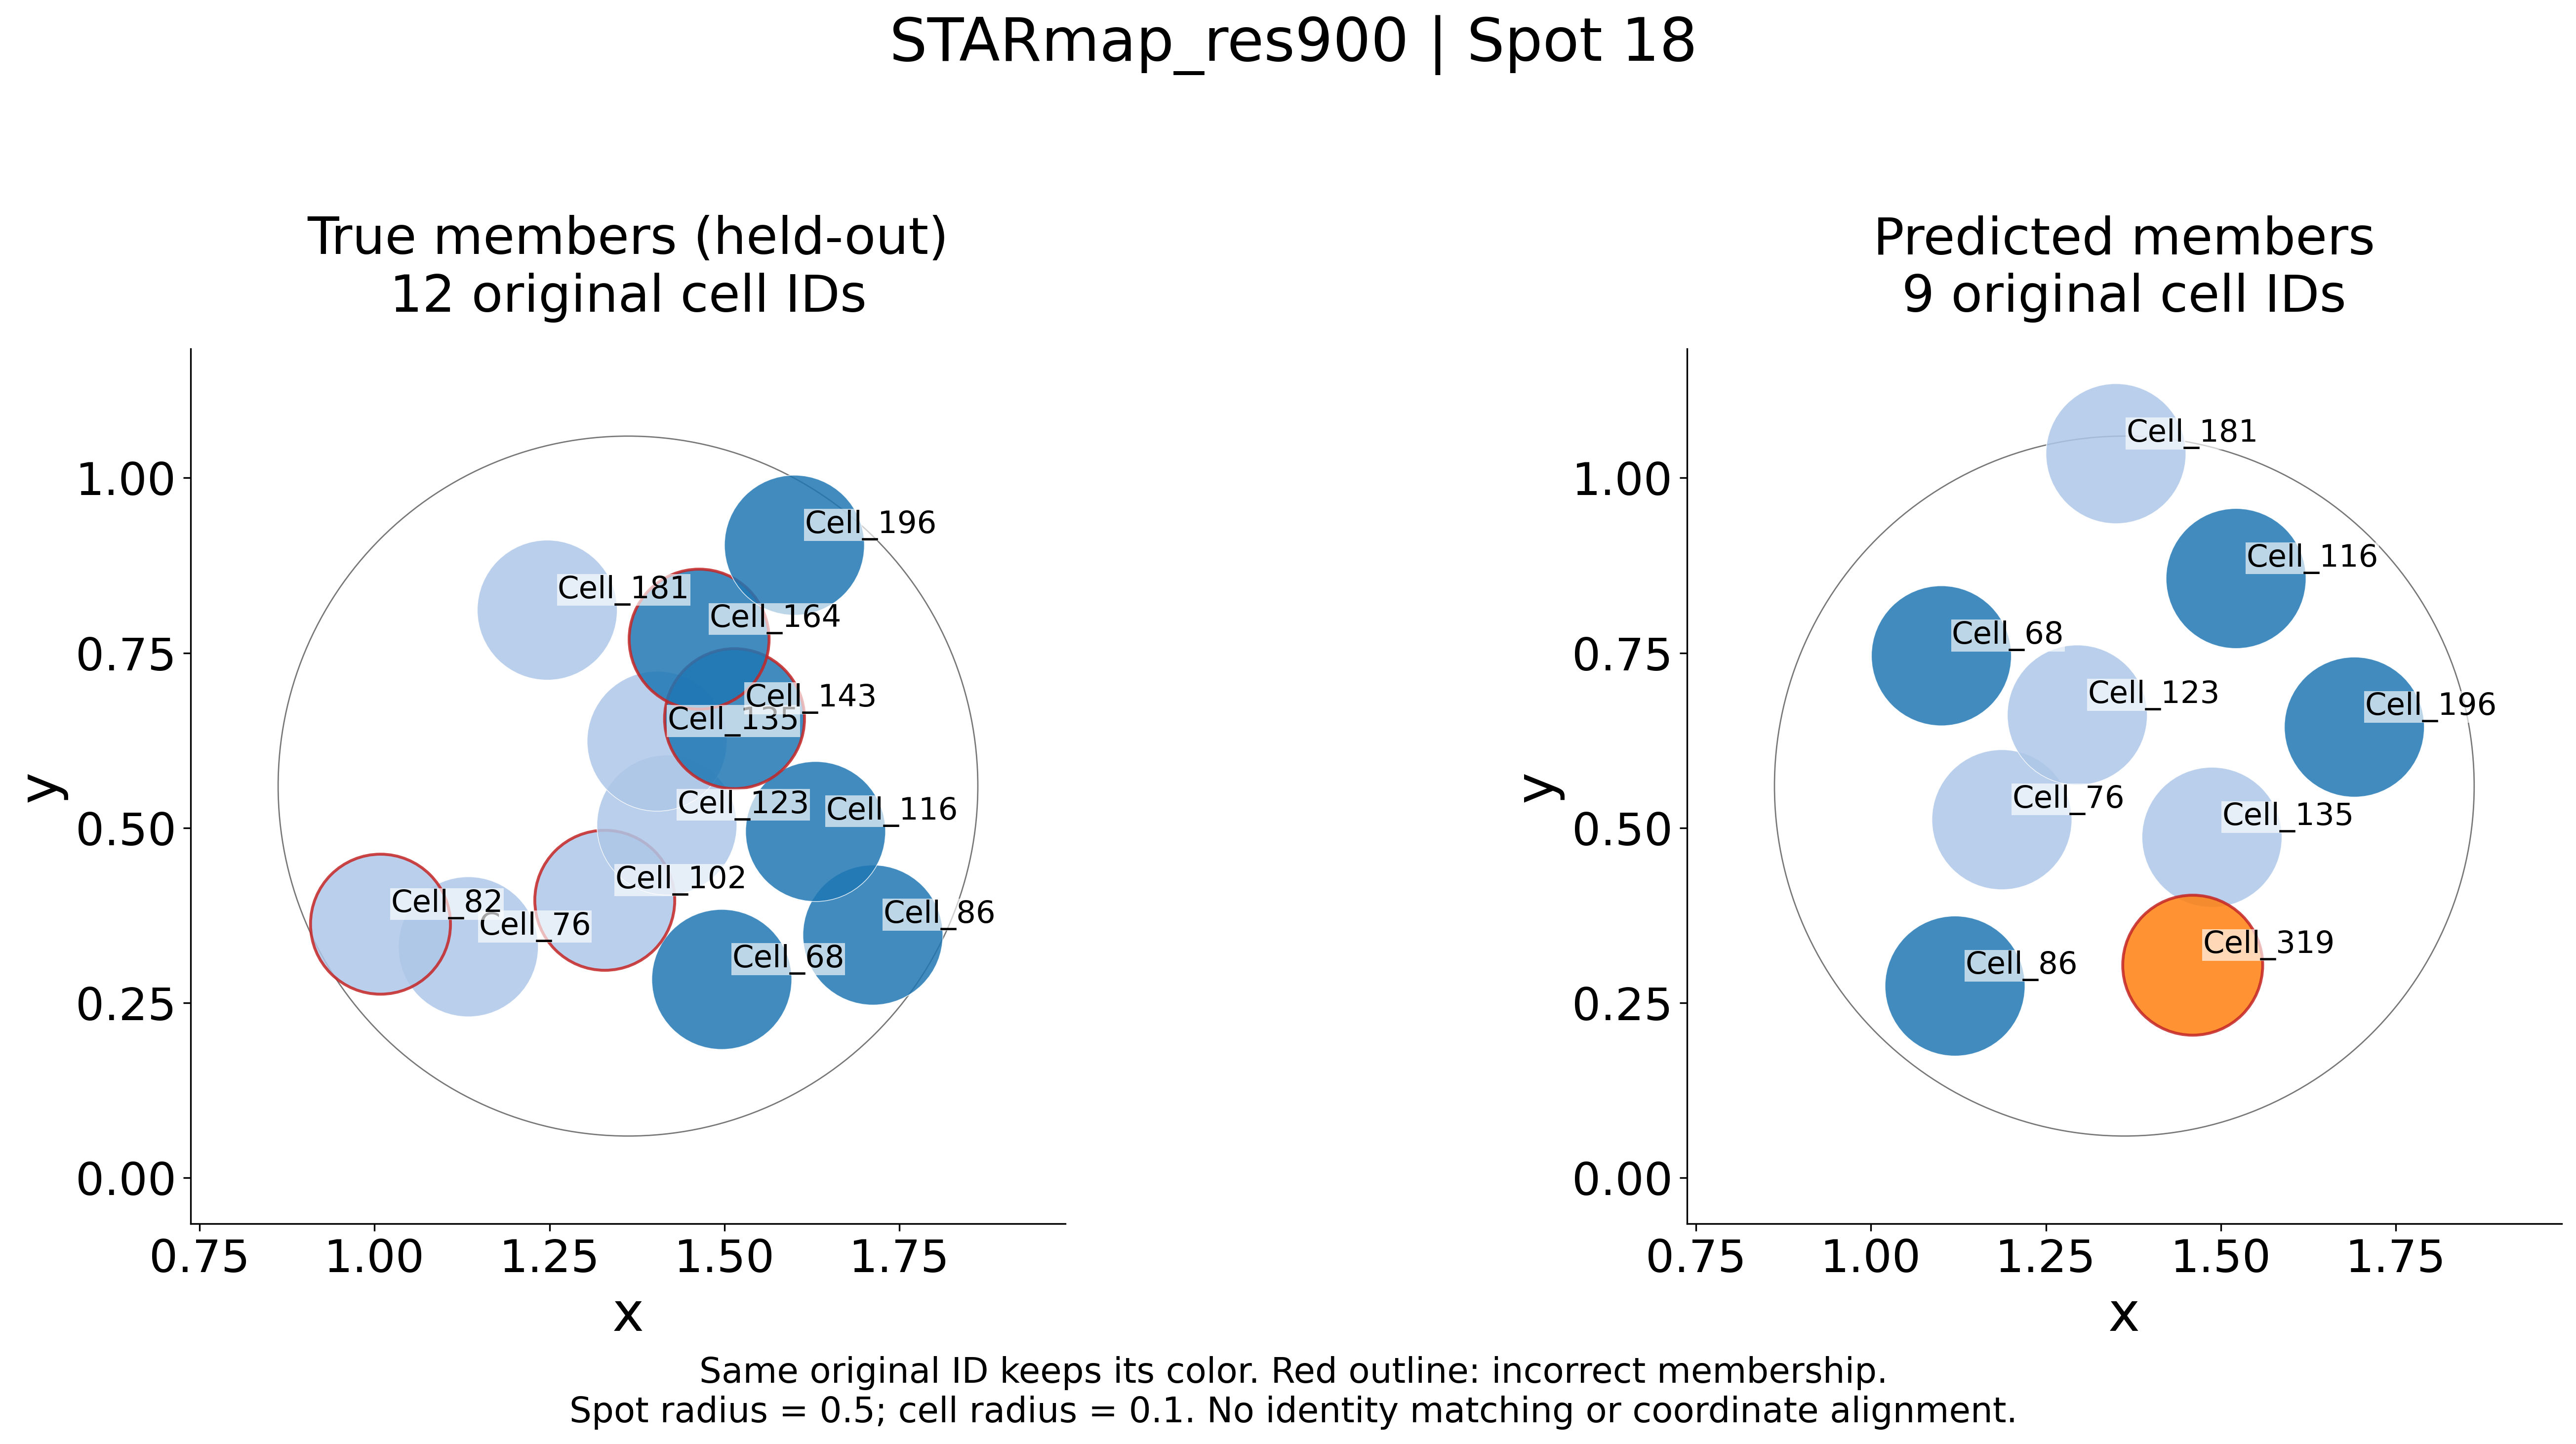

Finished. Results and figures: outputs\notebook_pretrained_visualization


In [7]:
SPOTS = {}  # Example: {'seqFISH+_res500': 27, 'STARmap_res900': 18}
for name, run in RUNS.items():
    prediction = run['prediction']
    counts = np.bincount(prediction['membership'], minlength=run['sp'].n_obs)
    default_spot = int(np.argmax(np.where((counts > 0) & (counts <= 20), counts, -1)))
    spot = SPOTS.get(name, default_spot)
    show(viz.plot_spot(run['observed'], prediction, run['truth'], run['folder'] / 'figures', name, spot=spot))
print('Finished. Results and figures:', OUT.relative_to(ROOT))